# Clasificación de dígitos con una red neuronal en PyTorch

Versión en **PyTorch** del ejemplo de clasificación de dígitos MNIST con una red densa.

**Al terminar este notebook podrás:**

- Cargar y preparar un conjunto de datos de imágenes.
- Definir una red neuronal densa con `nn.Sequential`.
- Entrenar la red con minibatches y seguir su progreso época a época.
- Evaluar la red con datos que nunca vio y mirar sus predicciones.

## Etapa 1: Carga de los datos.

Antes de comenzar a definir la red neuronal, cargamos la base de datos de interés. Para este ejemplo, usaremos la base de datos MNIST, la cual consiste en identificar dígitos escritos a mano alzada. Esta base de datos configura un problema de 10 clases, una clase por cada dígito numérico (0-9).

Se cargan las librerías necesarias. Fijamos también una semilla (`manual_seed`) para que los números aleatorios sean los mismos en cada ejecución y los resultados sean reproducibles.

In [1]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from torchvision import datasets
import matplotlib.pyplot as plt
from tqdm import tqdm

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.manual_seed(0)
print('Dispositivo:', device)

Dispositivo: cuda


Se carga la base de datos. MNIST trae 60000 imágenes para entrenamiento y 10000 para prueba (test).

In [2]:
mnist_train = datasets.MNIST(root='./data', train=True, download=True)
mnist_test = datasets.MNIST(root='./data', train=False, download=True)

# .data guarda las imágenes (uint8, forma (N, 28, 28)) y .targets las etiquetas (enteros 0-9),
# ya como tensores de PyTorch
x_train, y_train = mnist_train.data, mnist_train.targets
x_test, y_test = mnist_test.data, mnist_test.targets

Antes de usar los datos, conviene conocerlos: su forma, el rango de valores de los píxeles y cuántas imágenes hay de cada clase.

In [3]:
print('Imágenes de entrenamiento:', x_train.shape)   # (60000, 28, 28)
print('Etiquetas de entrenamiento:', y_train.shape)  # (60000,)
print('Valores de los píxeles: de', x_train.min().item(), 'a', x_train.max().item())
print('Imágenes por clase:', {int(d): int((y_train == d).sum()) for d in range(10)})

Imágenes de entrenamiento: torch.Size([60000, 28, 28])
Etiquetas de entrenamiento: torch.Size([60000])
Valores de los píxeles: de 0 a 255
Imágenes por clase: {0: 5923, 1: 6742, 2: 5958, 3: 6131, 4: 5842, 5: 5421, 6: 5918, 7: 6265, 8: 5851, 9: 5949}


Las imágenes tienen tamaño de 28x28 píxeles, en escala de grises. A continuación, se muestran algunos ejemplos.

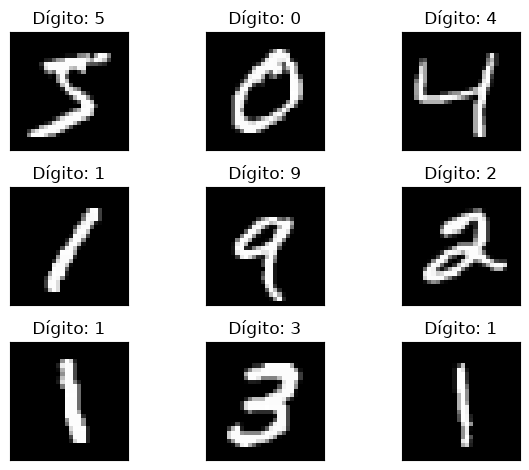

In [4]:
plt.figure()
for i in range(9):
    plt.subplot(3, 3, i+1)
    plt.imshow(x_train[i], cmap='gray', interpolation='none')
    plt.title(f"Dígito: {y_train[i].item()}")
    plt.xticks([])
    plt.yticks([])
plt.tight_layout()
plt.show()

Dado que este ejercicio es introductorio solo usaremos la forma más básica de una red neuronal, denominada densa (`nn.Linear` en PyTorch). Esta versión no tiene la capacidad de manipular imágenes en su forma original. Así, aplicaremos una etapa de preprocesamiento a cada imagen con el fin de que las imágenes sean compatibles con las entradas de la red.

Hacemos dos cosas:

1. **Aplastamiento (flatten):** convertimos cada imagen de 28x28 en un vector de 784 valores.
2. **Normalización:** los píxeles van de 0 a 255; los dividimos entre 255 para que queden entre 0 y 1. Las entradas pequeñas y en una escala común hacen que el entrenamiento sea más estable.

**Una advertencia:** al aplastar, la red deja de saber qué píxeles eran vecinos en la imagen; trata cada uno como un atributo independiente. Para MNIST esto basta, pero en la unidad de redes convolucionales veremos redes que sí aprovechan la estructura de la imagen. (En PyTorch también se puede aplastar dentro de la propia red con `nn.Flatten()`.)

In [5]:
# -1 significa "calcula esta dimensión por mí": se conservan todas las imágenes
# y cada una pasa de 28x28 a un vector de 784 atributos.
x_train_flat = x_train.reshape(-1, 28*28).float() / 255
x_test_flat = x_test.reshape(-1, 28*28).float() / 255

# Las etiquetas ya son enteros de tipo long (0-9), que es lo que CrossEntropyLoss espera
y_train_t = y_train
y_test_t = y_test

print('Entrenamiento:', x_train_flat.shape)
print('Prueba:', x_test_flat.shape)

Entrenamiento: torch.Size([60000, 784])
Prueba: torch.Size([10000, 784])


El aplastamiento convierte un arreglo de dos o más dimensiones en uno de una dimensión, **poniendo las filas una a continuación de otra**. Un ejemplo pequeño, con una imagen de 3x3:

In [6]:
example = torch.tensor([[1, 2, 3],
                       [4, 5, 6],
                       [7, 8, 9]])
print(example.reshape(-1))  # tensor([1, 2, 3, 4, 5, 6, 7, 8, 9])

tensor([1, 2, 3, 4, 5, 6, 7, 8, 9])


Se mantienen las mismas 60000 imágenes y cada una tiene ahora 784 atributos, porque 28*28=784.

### Separar un conjunto de validación

Si usáramos el conjunto de prueba para ir ajustando decisiones durante el entrenamiento, ya no sería una prueba "honesta": la red (y nosotros) habríamos visto esos datos. Por eso separamos tres conjuntos:

| Conjunto | Imágenes | Para qué sirve |
|---|---|---|
| Entrenamiento | 50000 | Calcular los pesos de la red |
| Validación | 10000 | Vigilar el desempeño época a época |
| Prueba (test) | 10000 | Evaluación final, una sola vez, al terminar |

In [7]:
# Mezclamos los índices de las 60000 imágenes y apartamos 10000 para validación
generator = torch.Generator().manual_seed(0)
perm = torch.randperm(len(x_train_flat), generator=generator)
val_idx, train_idx = perm[:10000], perm[10000:]

x_val_flat, y_val_t = x_train_flat[val_idx], y_train_t[val_idx]
x_train_flat, y_train_t = x_train_flat[train_idx], y_train_t[train_idx]

print('Entrenamiento:', x_train_flat.shape[0], '| Validación:', x_val_flat.shape[0], '| Prueba:', x_test_flat.shape[0])

Entrenamiento: 50000 | Validación: 10000 | Prueba: 10000


## Etapa 2: Definición de la red.

Ahora podemos empezar a construir la red neuronal para resolver el problema de clasificación planteado. En PyTorch una red se define como una clase que hereda de `nn.Module`, o de forma compacta con `nn.Sequential`. En este ejemplo usaremos `nn.Sequential`, una forma compacta de apilar las capas en orden.

**Vocabulario que usaremos:**

| Término | Significado |
|---|---|
| **Época (epoch)** | Una pasada completa por todas las imágenes de entrenamiento. |
| **Batch / minibatch** | Un grupo pequeño de imágenes con el que se calcula el error y se actualizan los pesos una vez. |
| **Iteración** | Una actualización de los pesos (un minibatch procesado). |
| **Logits** | Las 10 salidas de la red antes de convertirlas en probabilidades. |
| **Pérdida (loss)** | Número que mide qué tan mal predice la red. Entrenar es hacerlo bajar. |
| **Exactitud (accuracy)** | Fracción de imágenes que la red clasifica correctamente. |

### 2.1 Definición de la red usando nn.Sequential

Se define una red con tres capas: dos ocultas y una de salida. Para este ejemplo el tipo de capas usada es la lineal (densa), en unidades posteriores usaremos otro tipo de capas como las convolucionales y las recurrentes.

**Nota:** la última capa no aplica `softmax`. PyTorch entrega *logits* y la función de pérdida `nn.CrossEntropyLoss` aplica internamente `log-softmax`, por lo que recibe directamente las etiquetas enteras.

**Dos decisiones de diseño:**

- **ReLU** es la función de activación: deja pasar los valores positivos y convierte los negativos en 0, es decir, `ReLU(x) = max(0, x)`. Sin activaciones, apilar capas lineales equivaldría a una sola capa lineal.
- Los tamaños de las capas ocultas (1024 y 512) los elegimos nosotros: son *hiperparámetros* y no hay un valor único correcto. En cambio, la entrada (784) y la salida (10) vienen fijadas por los datos.

Dejamos la definición dentro de una función, `make_model()`, para poder crear redes nuevas (con pesos nuevos) cuando las necesitemos.

In [8]:
def make_model():
    return nn.Sequential(
        # La primera capa tiene 1024 unidades con activación ReLU. Entrada de tamaño 784.
        nn.Linear(784, 1024),
        nn.ReLU(),
        # La segunda capa presenta 512 unidades con activación ReLU.
        nn.Linear(1024, 512),
        nn.ReLU(),
        # La tercera capa, corresponde a la capa de salida: tantas unidades como clases (10).
        nn.Linear(512, 10),
    ).to(device)

model = make_model()

Con `print(model)` y el conteo de parámetros podemos verificar las capas que definimos y la cantidad de parámetros en cada capa.

Cada capa `nn.Linear(entrada, salida)` tiene una matriz de pesos con `entrada × salida` valores (PyTorch la guarda con forma `(salida, entrada)`, como se ve abajo) y un sesgo por cada unidad de salida. Por ejemplo, la primera capa tiene 784 × 1024 + 1024 = 803,840 parámetros.

In [9]:
print(model)
print()
for name, p in model.named_parameters():
    print(f'{name:12s} {str(tuple(p.shape)):16s} {p.numel():>10,}')

total = sum(p.numel() for p in model.parameters())
print(f'\nTotal de parámetros: {total:,}')

Sequential(
  (0): Linear(in_features=784, out_features=1024, bias=True)
  (1): ReLU()
  (2): Linear(in_features=1024, out_features=512, bias=True)
  (3): ReLU()
  (4): Linear(in_features=512, out_features=10, bias=True)
)

0.weight     (1024, 784)         802,816
0.bias       (1024,)               1,024
2.weight     (512, 1024)         524,288
2.bias       (512,)                  512
4.weight     (10, 512)             5,120
4.bias       (10,)                    10

Total de parámetros: 1,333,770


### 2.2 Función de pérdida y optimizador

La función de costo y el optimizador se definen por separado. Más adelante crearemos redes nuevas y, con cada red, un optimizador nuevo: cada optimizador está atado a los parámetros de *su* red.

In [10]:
# 1. Para la pérdida se usa CrossEntropyLoss (entropía cruzada con etiquetas enteras): recibe
#    logits y etiquetas enteras, por eso no necesitamos one-hot ni softmax en la salida.
# 2. Utilizamos el optimizador SGD, un algoritmo basado en gradiente.
#    lr (learning rate) es el tamaño del paso con que se actualizan los pesos;
#    lr=0.01 es un valor de referencia habitual para SGD.
# 3. La métrica de desempeño será la exactitud (accuracy), que calculamos con la función de abajo.
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.01)

def accuracy(logits, y):
    # La clase predicha es la de mayor logit; se compara con la etiqueta real
    return (logits.argmax(dim=1) == y).float().mean().item()

### 2.3 Entrenamiento

Ahora es momento de entrenar la red neuronal, lo cual corresponde a calcular los parámetros de la red. Lo haremos en dos pasos: primero con el ciclo más básico posible y luego con una versión completa.

### 2.3.1 Ciclo de entrenamiento básico

Este es el ciclo de entrenamiento más básico posible en PyTorch. Cada época usa **todas** las imágenes de entrenamiento de una sola vez, así que hay una única actualización de pesos por época.

Lo que hace cada paso:

1. **`optimizer.zero_grad()`**: borra los gradientes que quedaron de la iteración anterior. Si no se borran, PyTorch los acumula.
2. **Forward, `model(x)`**: la red recibe los datos y calcula su predicción.
3. **Pérdida, `loss_fn(logits, y)`**: mide qué tan lejos está la predicción de la etiqueta real.
4. **`loss.backward()`**: calcula el gradiente de la pérdida respecto a cada parámetro de la red.
5. **`optimizer.step()`**: usa esos gradientes para actualizar los pesos de la red.

Usamos una red nueva (`basic_model`) para no mezclar este experimento con el entrenamiento de la sección 2.3.2.

In [11]:
basic_model = make_model()
basic_optimizer = torch.optim.SGD(basic_model.parameters(), lr=0.01)

epochs = 20
x = x_train_flat.to(device)
y = y_train_t.to(device)

for epoch in range(epochs):
    basic_optimizer.zero_grad()      # 1. limpiar los gradientes de la iteración anterior
    logits = basic_model(x)          # 2. forward: predicción de la red
    loss = loss_fn(logits, y)        # 3. error entre predicción y etiqueta
    loss.backward()                  # 4. backward: gradientes de cada parámetro
    basic_optimizer.step()           # 5. actualizar los pesos con los gradientes
    print(f'Epoch {epoch+1}/{epochs} - loss: {loss.item():.4f}')

Epoch 1/20 - loss: 2.3045
Epoch 2/20 - loss: 2.3039
Epoch 3/20 - loss: 2.3033
Epoch 4/20 - loss: 2.3027


Epoch 5/20 - loss: 2.3021
Epoch 6/20 - loss: 2.3015
Epoch 7/20 - loss: 2.3008
Epoch 8/20 - loss: 2.3002
Epoch 9/20 - loss: 2.2996
Epoch 10/20 - loss: 2.2990


Epoch 11/20 - loss: 2.2984
Epoch 12/20 - loss: 2.2978
Epoch 13/20 - loss: 2.2972
Epoch 14/20 - loss: 2.2966


Epoch 15/20 - loss: 2.2960
Epoch 16/20 - loss: 2.2954
Epoch 17/20 - loss: 2.2948
Epoch 18/20 - loss: 2.2942
Epoch 19/20 - loss: 2.2936
Epoch 20/20 - loss: 2.2930


Observa dos cosas:

- La pérdida inicial es cercana a **2.30**, que es ln(10). Tiene sentido: con 10 clases, una red que apenas empieza es como adivinar al azar. Es una buena señal de que todo está bien configurado.
- Después de 20 épocas la pérdida bajó muy poco, porque solo hicimos **20 actualizaciones** de los pesos. Con minibatches haremos muchas más: en la sección 2.3.2 la pérdida baja de 2.3 a cerca de 0.2 en el mismo número de épocas.

### 2.3.2 Entrenamiento completo

Es el mismo ciclo de la sección 2.3.1, con datos y seguimiento adicionales:

- **Minibatches**: en lugar de usar todas las imágenes de una vez, el entrenamiento se divide en minibatches de 128 imágenes y los pesos se actualizan después de cada uno. Con 50000 imágenes son 50000 / 128 ≈ 391 actualizaciones por época, en lugar de 1.
- **Validación**: en cada época medimos el desempeño sobre el conjunto de validación, para ver si la red generaliza.
- **Historial**: guardamos la pérdida y la exactitud de cada época para graficarlas después.
- **Progreso y GPU**: mostramos una barra de progreso con `tqdm` y movemos los datos a la GPU cuando está disponible.
- **`model.train()` y `model.eval()`**: indican si la red está entrenando o evaluando. En esta red no cambian nada, pero algunas capas (como Dropout o BatchNorm, que veremos más adelante) se comportan distinto en cada modo, así que es buena costumbre escribirlos siempre.

In [12]:
epochs = 20
batch_size = 128

# Datos en la GPU (si existe) antes del entrenamiento
x_train_dev, y_train_dev = x_train_flat.to(device), y_train_t.to(device)
x_val_dev, y_val_dev = x_val_flat.to(device), y_val_t.to(device)

# El DataLoader entrega los datos en minibatches, mezclados en cada época (shuffle)
train_loader = DataLoader(TensorDataset(x_train_dev, y_train_dev), batch_size=batch_size, shuffle=True)

# Red nueva, para entrenar desde cero
model = make_model()
optimizer = torch.optim.SGD(model.parameters(), lr=0.01)

history = {'loss': [], 'accuracy': [], 'val_loss': [], 'val_accuracy': []}

# Barra de progreso de tqdm: una línea que se llena época tras época
pbar = tqdm(range(epochs), desc='Entrenamiento', unit='época')

for epoch in pbar:
    # --- entrenamiento por minibatches ---
    model.train()
    running_loss, running_acc, n = 0.0, 0.0, 0
    for xb, yb in train_loader:
        optimizer.zero_grad()
        logits = model(xb)
        loss = loss_fn(logits, yb)
        loss.backward()
        optimizer.step()
        # Acumulamos ponderando por el tamaño del minibatch (el último puede ser más pequeño)
        running_loss += loss.item() * len(yb)
        running_acc += accuracy(logits, yb) * len(yb)
        n += len(yb)
    history['loss'].append(running_loss / n)
    history['accuracy'].append(running_acc / n)

    # --- validación (sin calcular gradientes, solo se mide) ---
    model.eval()
    with torch.no_grad():
        val_logits = model(x_val_dev)
        val_loss = loss_fn(val_logits, y_val_dev).item()
        val_acc = accuracy(val_logits, y_val_dev)
    history['val_loss'].append(val_loss)
    history['val_accuracy'].append(val_acc)

    # Métricas que se muestran al final de la barra
    pbar.set_postfix(loss=f"{history['loss'][-1]:.4f}", accuracy=f"{history['accuracy'][-1]:.4f}",
                     val_loss=f"{val_loss:.4f}", val_accuracy=f"{val_acc:.4f}")

pbar.close()

Entrenamiento: 100%|██████████| 20/20 [00:05<00:00,  3.40época/s, accuracy=0.9354, loss=0.2253, val_accuracy=0.9333, val_loss=0.2396]


## Etapa 3: Evaluación

Ahora usamos el conjunto de **prueba**, que la red no vio ni durante el entrenamiento ni durante la validación. Este número es la mejor estimación de qué tan bien funcionará la red con imágenes nuevas.

In [13]:
x_test_dev, y_test_dev = x_test_flat.to(device), y_test_t.to(device)

model.eval()
with torch.no_grad():
    test_logits = model(x_test_dev)
    test_loss = loss_fn(test_logits, y_test_dev).item()
    test_acc = accuracy(test_logits, y_test_dev)
print(f'Pérdida en prueba: {test_loss:.4f}')
print(f'Exactitud en prueba: {test_acc:.4f}')

Pérdida en prueba: 0.2234
Exactitud en prueba: 0.9359


### Curvas de entrenamiento

Graficamos la evolución de la exactitud y de la pérdida. Qué buscar:

- La pérdida **baja** y la exactitud **sube** época tras época: la red está aprendiendo.
- Si la curva de entrenamiento sigue mejorando pero la de validación se estanca o empeora, la red está memorizando los datos de entrenamiento (**sobreajuste**).

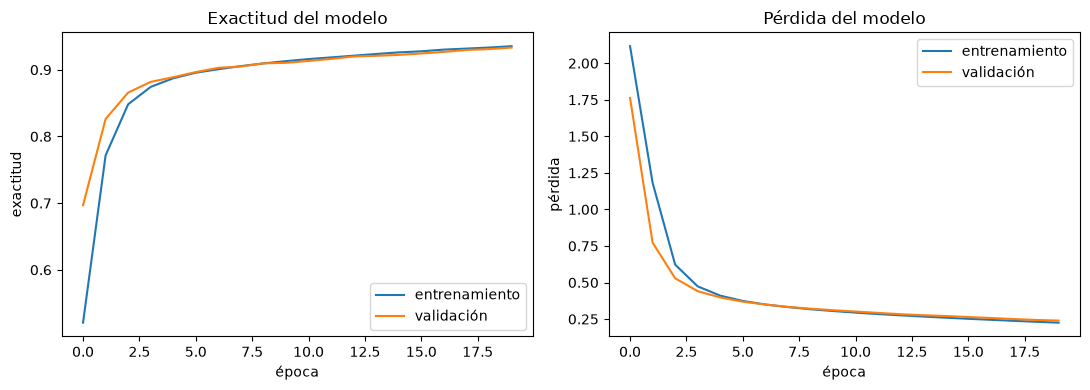

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(history['accuracy'], label='entrenamiento')
axes[0].plot(history['val_accuracy'], label='validación')
axes[0].set_title('Exactitud del modelo')
axes[0].set_xlabel('época')
axes[0].set_ylabel('exactitud')
axes[0].legend()

axes[1].plot(history['loss'], label='entrenamiento')
axes[1].plot(history['val_loss'], label='validación')
axes[1].set_title('Pérdida del modelo')
axes[1].set_xlabel('época')
axes[1].set_ylabel('pérdida')
axes[1].legend()

plt.tight_layout()
plt.show()

**Qué vemos en estas curvas:** la pérdida baja y la exactitud sube sin parar, y las curvas de entrenamiento y validación van casi pegadas. Eso significa que **no hay sobreajuste**: la red generaliza igual de bien a datos que no vio. Además, a las 20 épocas las curvas todavía no se aplanan del todo, así que entrenar más épocas probablemente seguiría mejorando el resultado (el ejercicio 5 lo explora).

### Ejemplos de predicciones

La exactitud nos dice cuántos errores hay, pero no cuáles son. Veamos las primeras 12 imágenes de prueba que la red clasificó mal: ¿te equivocarías tú también?

La red se equivocó en 641 de 10000 imágenes de prueba


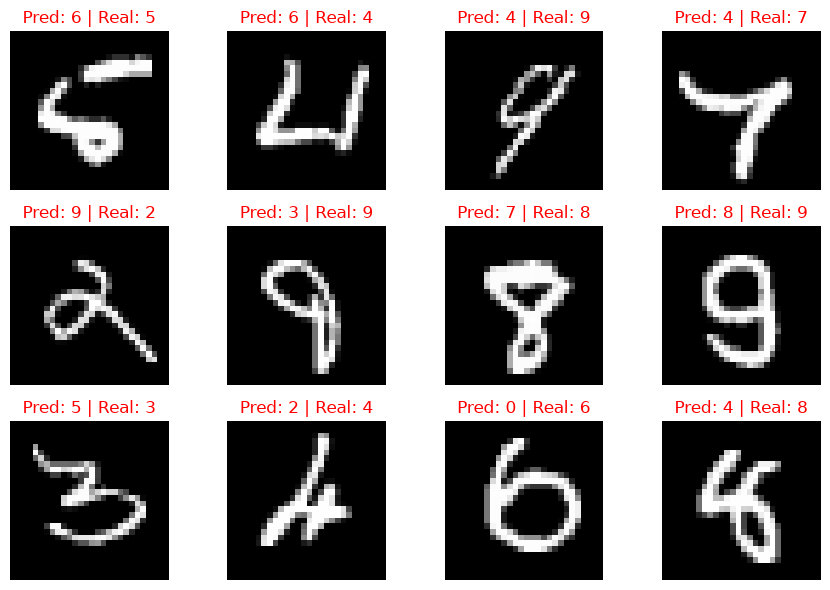

In [15]:
predictions = test_logits.argmax(dim=1).cpu()

# Índices de las imágenes de prueba donde la predicción no coincide con la etiqueta real
wrong = (predictions != y_test).nonzero().flatten()[:12]
print(f'La red se equivocó en {int((predictions != y_test).sum())} de {len(y_test)} imágenes de prueba')

plt.figure(figsize=(9, 6))
for k, i in enumerate(wrong):
    plt.subplot(3, 4, k+1)
    plt.imshow(x_test[i], cmap='gray')
    plt.title(f'Pred: {predictions[i].item()} | Real: {y_test[i].item()}', color='red')
    plt.axis('off')
plt.tight_layout()
plt.show()

### ¿Qué hay detrás de una predicción?

La red entrega 10 *logits* por imagen. Si les aplicamos `softmax`, se convierten en probabilidades que suman 1. La clase predicha es la de mayor probabilidad. Veamos las de la primera imagen de prueba:

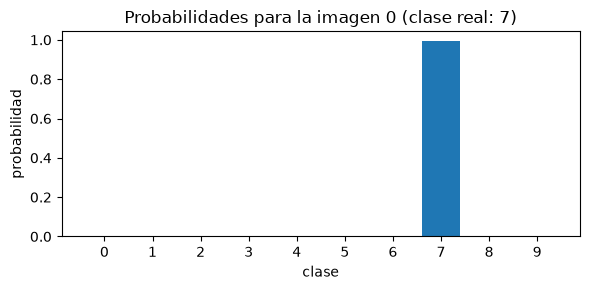

Suma de las probabilidades: 0.9999998807907104


In [16]:
probs = torch.softmax(test_logits[0], dim=0).cpu()   # logits -> probabilidades

plt.figure(figsize=(6, 3))
plt.bar(range(10), probs)
plt.xticks(range(10))
plt.xlabel('clase')
plt.ylabel('probabilidad')
plt.title(f'Probabilidades para la imagen 0 (clase real: {y_test[0].item()})')
plt.tight_layout()
plt.show()
print('Suma de las probabilidades:', probs.sum().item())

### Matriz de confusión

Para ver qué dígitos confunde la red, contamos para cada clase real (filas) cuántas veces predijo cada clase (columnas). La diagonal son los aciertos; fuera de la diagonal están las confusiones.

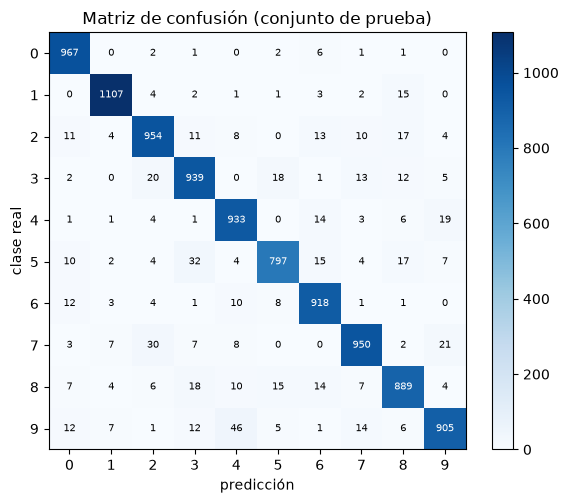

In [17]:
# confusion[real, predicción] = número de imágenes con esa combinación
confusion = torch.zeros(10, 10, dtype=torch.long)
confusion.index_put_((y_test, predictions), torch.ones_like(y_test), accumulate=True)

plt.figure(figsize=(6, 5))
plt.imshow(confusion, cmap='Blues')
for real in range(10):
    for pred in range(10):
        count = confusion[real, pred].item()
        plt.text(pred, real, count, ha='center', va='center',
                 color='white' if count > confusion.max() / 2 else 'black', fontsize=7)
plt.xticks(range(10))
plt.yticks(range(10))
plt.xlabel('predicción')
plt.ylabel('clase real')
plt.title('Matriz de confusión (conjunto de prueba)')
plt.colorbar()
plt.tight_layout()
plt.show()

Las confusiones tienen sentido visual: por ejemplo, el 9 se confunde con el 4 (46 veces) y el 7 con el 2 (30 veces), porque son dígitos que se parecen al escribirlos a mano.

## Etapa 4: Organizar el código en una clase

Todo lo que hicimos hasta aquí funciona, pero está en celdas sueltas. Cuando queremos probar otra red o repetir el entrenamiento, hay que copiar y pegar mucho código.

Una forma más compacta es agrupar todo en una **clase** que tenga un método por cada tarea:

| Método | Qué hace |
|---|---|
| `__init__` | Crea la red, la función de pérdida y el optimizador. |
| `train_epoch` | Recorre los minibatches de una época y actualiza los pesos. |
| `evaluate` | Mide pérdida y exactitud sobre un conjunto, sin entrenar. |
| `fit` | Repite `train_epoch` y `evaluate` por varias épocas y guarda el historial. |
| `predict` | Devuelve la clase predicha para unas imágenes. |

Es exactamente el mismo código de las secciones anteriores, solo reorganizado. La clase usa `device` y `accuracy`, que definimos antes en el notebook.

In [18]:
class MnistClassifier:
    def __init__(self, hidden_sizes=(1024, 512), lr=0.01):
        # Se construye la lista de capas a partir de los tamaños indicados
        layers, in_features = [], 784
        for size in hidden_sizes:
            layers += [nn.Linear(in_features, size), nn.ReLU()]
            in_features = size
        layers.append(nn.Linear(in_features, 10))

        self.net = nn.Sequential(*layers).to(device)
        self.loss_fn = nn.CrossEntropyLoss()
        self.optimizer = torch.optim.SGD(self.net.parameters(), lr=lr)
        self.history = {'loss': [], 'accuracy': [], 'val_loss': [], 'val_accuracy': []}

    def train_epoch(self, loader):
        # Una época: recorre todos los minibatches y actualiza los pesos
        self.net.train()
        total_loss, total_acc, n = 0.0, 0.0, 0
        for xb, yb in loader:
            self.optimizer.zero_grad()
            logits = self.net(xb)
            loss = self.loss_fn(logits, yb)
            loss.backward()
            self.optimizer.step()
            total_loss += loss.item() * len(yb)
            total_acc += accuracy(logits, yb) * len(yb)
            n += len(yb)
        return total_loss / n, total_acc / n

    def evaluate(self, x, y):
        # Mide el desempeño sin entrenar (sin calcular gradientes)
        self.net.eval()
        with torch.no_grad():
            logits = self.net(x)
            return self.loss_fn(logits, y).item(), accuracy(logits, y)

    def fit(self, train_loader, x_val, y_val, epochs=20):
        pbar = tqdm(range(epochs), desc='Entrenamiento', unit='época')
        for epoch in pbar:
            loss, acc = self.train_epoch(train_loader)
            val_loss, val_acc = self.evaluate(x_val, y_val)
            for key, value in zip(self.history, (loss, acc, val_loss, val_acc)):
                self.history[key].append(value)
            pbar.set_postfix(loss=f"{loss:.4f}", accuracy=f"{acc:.4f}",
                             val_loss=f"{val_loss:.4f}", val_accuracy=f"{val_acc:.4f}")

    def predict(self, x):
        # Devuelve la clase (0-9) predicha para cada imagen
        self.net.eval()
        with torch.no_grad():
            return self.net(x).argmax(dim=1)

Con la clase definida, entrenar una red completa se reduce a unas pocas líneas. Además, probar otra arquitectura o otro `lr` es cambiar un argumento. Para no gastar el conjunto de prueba (que reservamos para una evaluación final), medimos el resultado en validación:

In [19]:
clf = MnistClassifier(hidden_sizes=(1024, 512), lr=0.01)
clf.fit(train_loader, x_val_dev, y_val_dev, epochs=20)

val_loss, val_acc = clf.evaluate(x_val_dev, y_val_dev)
print(f'Pérdida en validación: {val_loss:.4f} | Exactitud en validación: {val_acc:.4f}')
print('Primeras 10 predicciones:', clf.predict(x_test_dev[:10]).tolist())
print('Etiquetas reales:        ', y_test[:10].tolist())

Entrenamiento: 100%|██████████| 20/20 [00:05<00:00,  3.40época/s, accuracy=0.9372, loss=0.2213, val_accuracy=0.9336, val_loss=0.2355]


Pérdida en validación: 0.2355 | Exactitud en validación: 0.9336
Primeras 10 predicciones: [7, 2, 1, 0, 4, 1, 4, 9, 6, 9]
Etiquetas reales:         [7, 2, 1, 0, 4, 1, 4, 9, 5, 9]


La clase `MnistClassifier` guarda su propio `history`, así que se pueden graficar las curvas igual que antes con `clf.history`. Esta forma de organizar el código es la que veremos con frecuencia en proyectos reales.

## Resumen

- Los datos se **preprocesan** (aplastar y normalizar) y se separan en entrenamiento, validación y prueba.
- Una red densa se define apilando capas `nn.Linear` y activaciones con `nn.Sequential`.
- Entrenar es repetir cinco pasos: `zero_grad`, forward, pérdida, `backward` y `step`.
- Usar **minibatches** da muchas más actualizaciones por época que usar todos los datos de una vez.
- El desempeño real se mide en el conjunto de **prueba**, una sola vez al final.
- Todo el flujo se puede agrupar en una **clase** con métodos como `fit`, `evaluate` y `predict`, para reutilizarlo fácilmente.

## Ejercicios

Modifica un valor a la vez, vuelve a entrenar y observa cómo cambian las curvas. Para los ejercicios 1, 2, 4 y 5 ejecuta desde la sección 2.3.2; para el 3 ejecuta desde la sección 2.1, porque ahí se define `make_model()`.

1. Cambia `lr` a `0.001` y luego a `0.1`. ¿Qué pasa con la velocidad de aprendizaje? (Pista: un `lr` más pequeño da pasos más cortos.)
2. Cambia `batch_size` a `32` y luego a `1024`. ¿Cómo cambia el tiempo por época y la exactitud? (Pista: cuenta cuántas actualizaciones hay por época.)
3. Quita la capa oculta de 512 unidades (ajusta la capa de salida a `nn.Linear(1024, 10)`). ¿La exactitud empeora?
4. Cambia el optimizador a `torch.optim.Adam(model.parameters(), lr=0.001)`. ¿Aprende más rápido?
5. Cambia `epochs` a `5` y luego a `60`. ¿Hasta qué época sigue mejorando la validación? ¿Aparece sobreajuste?